# 04 · Resultados e o que as avaliações mostram

Este notebook reúne os gráficos do README com a explicação de cada um. O código dos gráficos
fica em [`scripts/make_figures.py`](../scripts/make_figures.py), então notebook e README usam
exatamente as mesmas figuras (salvas em `results/figures/`).

Roda localmente, sem GPU: `uv run jupyter nbconvert --to notebook --execute --inplace notebooks/04_insights.ipynb`.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
import make_figures as mf  # noqa: E402

## 1. Comparação dos modelos no teste ouro

Os quatro modelos foram avaliados nas mesmas 150 avaliações reais, revisadas à mão e nunca
vistas no treino.

In [2]:
rows = []
for name, label in mf.MODELS:
    m = json.loads((ROOT / "results" / f"{name}.json").read_text(encoding="utf-8"))["metrics"]
    rows.append(
        {"modelo": label, **{title.replace("\n", " "): m[key] for key, title in mf.METRICS}}
    )
pd.DataFrame(rows).set_index("modelo").round(3)

,Aspectos (macro-F1),Problema principal (acurácia),Problema principal (macro-F1),Precisa de contato (F1)
modelo,,,,
Gemini (professor),0.970,0.960,0.921,0.956
"Qwen 1,5B + LoRA",0.869,0.853,0.760,0.917
"Qwen 0,5B + LoRA",0.780,0.760,0.557,0.887
TF-IDF + reg. logística,0.690,0.740,0.632,0.904


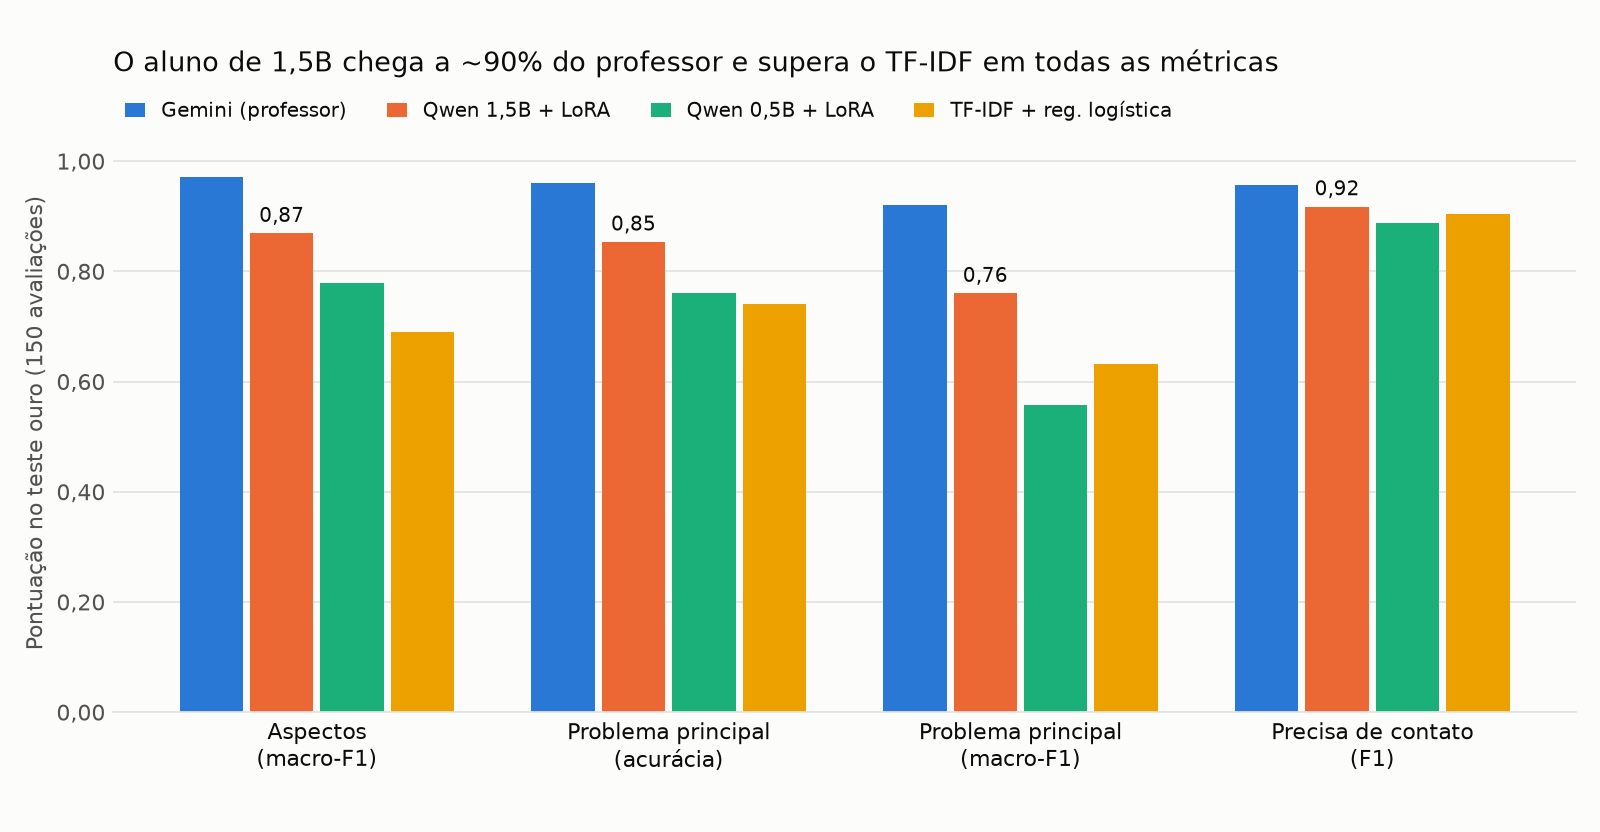

In [3]:
display(Image(mf.model_comparison()))

**Leitura:** o aluno de 1,5B chega a cerca de 90% do professor e supera o TF-IDF em todas as
métricas. O ganho do 0,5B para o 1,5B aparece sobretudo no macro-F1 do problema principal
(0,56 → 0,76), puxado pelas classes raras. Detalhes e análise de erros no README.

## 2. A nota não basta para priorizar o atendimento

Daqui em diante, os gráficos usam os rótulos do professor (Gemini) nas 2.000 avaliações do
pool, que foi amostrado com 400 avaliações por nota.

In [4]:
df = mf.pool_labels()
df.groupby("score")["needs_contact"].agg(avaliacoes="size", precisam_contato="mean").round(3)

,avaliacoes,precisam_contato
score,,
1,400,0.832
2,400,0.632
3,400,0.402
4,400,0.105
5,400,0.022


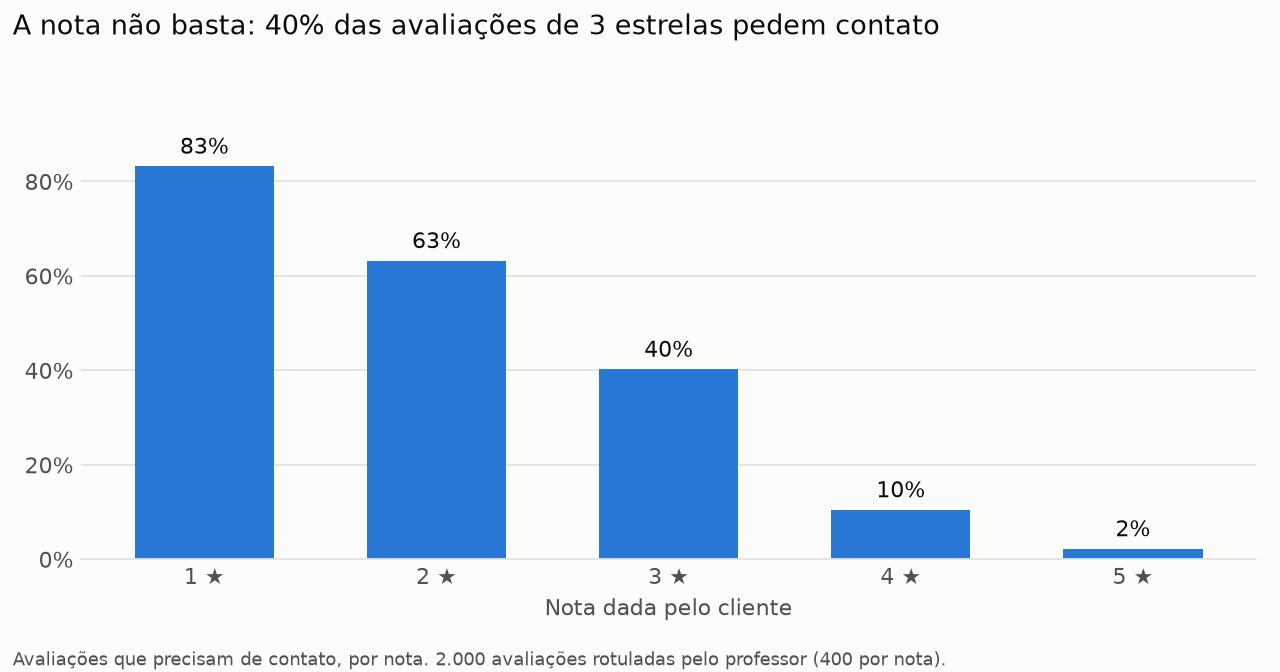

In [5]:
display(Image(mf.contact_by_score(df)))

**Leitura:** 40% das avaliações de 3 estrelas e 10% das de 4 estrelas descrevem um problema
sem solução (item faltando, pedido que não chegou, produto com defeito). Uma triagem só pela
nota deixaria esses clientes de fora; o diagnóstico do modelo os encontra.

## 3. Do que os clientes reclamam

A amostra tem a mesma quantidade de avaliações por nota, mas no conjunto real quase metade
das avaliações com texto tem 5 estrelas. Por isso cada avaliação é reponderada pela
proporção real da sua nota, para estimar o conjunto inteiro.

In [6]:
population = mf.load_reviews()["score"].value_counts(normalize=True).sort_index()
sample = df["score"].value_counts(normalize=True).sort_index()
pd.DataFrame(
    {"no conjunto real": population, "na amostra": sample, "peso": population / sample}
).round(3)

,no conjunto real,na amostra,peso
score,,,
1,0.230,0.2,1.148
2,0.056,0.2,0.282
3,0.090,0.2,0.448
4,0.141,0.2,0.705
5,0.483,0.2,2.417


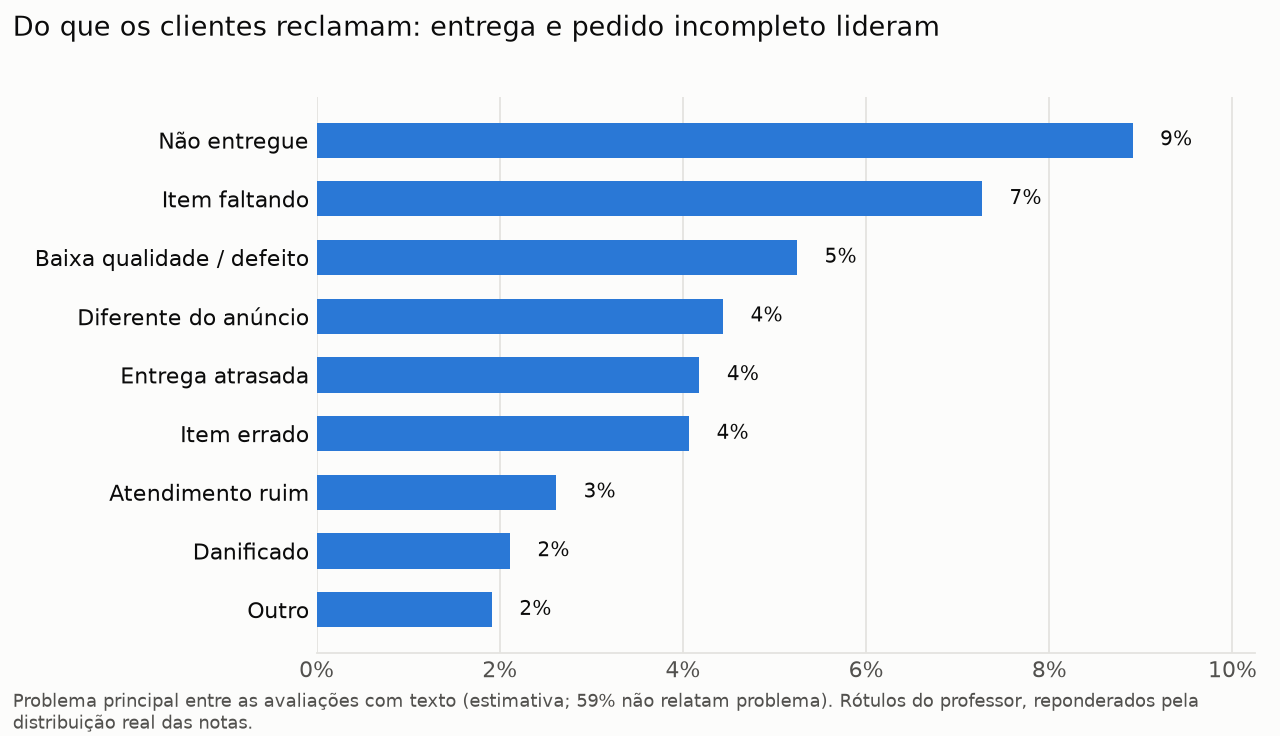

In [7]:
display(Image(mf.main_issues(df)))

**Leitura:** pedido não entregue (9%) e item faltando (7%) são os problemas mais citados,
à frente da qualidade do produto (5%). Ou seja, a maior parte das reclamações é de logística
e de separação do pedido, não do produto em si. 59% das avaliações com texto não relatam
problema.

**Ressalva:** estes números vêm dos rótulos do professor, que concordou com a revisão humana
em cerca de 96% dos casos no campo `main_issue` do teste ouro.